# Détection d'Anomalies par Autoencodeur Fédéré (Flower) — Version Améliorée

**Dataset :** `creditcard.csv`(https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) — Transactions bancaires et détection de fraude  
**Objectif :** Implémenter un système de détection d'anomalies basé sur un autoencodeur entraîné en apprentissage fédéré avec le framework **Flower (flwr)**.




## 1. Installation des dépendances


In [1]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install flwr -q



[notice] A new release of pip is available: 23.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Exploration et prétraitement des données
Le dataset contient des transactions bancaires. La colonne `Class` vaut 0 (normal) ou 1 (fraude).  
On n'utilise que les transactions **normales** pour entraîner l'autoencodeur.


In [3]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)

warnings.filterwarnings('ignore')
np.random.seed(42)


In [4]:
df = pd.read_csv('creditcard.csv')

print('Shape:', df.shape)
print('\nDistribution Class:')
print(df['Class'].value_counts())
df.head()


Shape: (284807, 31)

Distribution Class:
Class
0    284315
1       492
Name: count, dtype: int64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


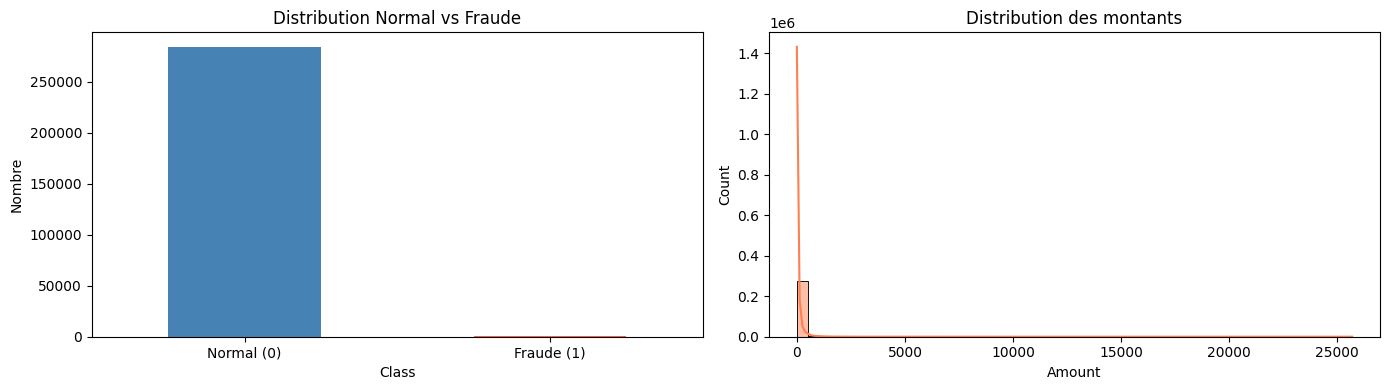

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['Class'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue', 'tomato'])
axes[0].set_title('Distribution Normal vs Fraude')
axes[0].set_xticklabels(['Normal (0)', 'Fraude (1)'], rotation=0)
axes[0].set_ylabel('Nombre')
sns.histplot(df['Amount'], bins=50, kde=True, ax=axes[1], color='coral')
axes[1].set_title('Distribution des montants')
axes[1].set_xlabel('Amount')
plt.tight_layout()
plt.show()


In [6]:
FEATURES = [col for col in df.columns if col != 'Class']
INPUT_DIM = len(FEATURES)
AMOUNT_IDX = FEATURES.index('Amount')

X = df[FEATURES].values
y = df['Class'].values

X_normal  = X[y == 0]
X_anomaly = X[y == 1]

print(f'INPUT_DIM : {INPUT_DIM}')
print(f'Normaux   : {X_normal.shape[0]}')
print(f'Anomalies : {X_anomaly.shape[0]}')


INPUT_DIM : 30
Normaux   : 284315
Anomalies : 492


In [7]:
X_train_normal, X_holdout_normal = train_test_split(
    X_normal, test_size=0.2, random_state=42
)
X_val_normal, X_test_normal = train_test_split(
    X_holdout_normal, test_size=0.5, random_state=42
)
X_val_anomaly, X_test_anomaly = train_test_split(
    X_anomaly, test_size=0.5, random_state=42
)

amount_train_raw = X_train_normal[:, AMOUNT_IDX].copy()
amount_val_raw = X_val_normal[:, AMOUNT_IDX].copy()
amount_test_raw = X_test_normal[:, AMOUNT_IDX].copy()

scaler = StandardScaler()
X_train_normal_scaled = scaler.fit_transform(X_train_normal)
X_val_normal_scaled = scaler.transform(X_val_normal)
X_test_normal_scaled = scaler.transform(X_test_normal)
X_val_anomaly_scaled = scaler.transform(X_val_anomaly)
X_test_anomaly_scaled = scaler.transform(X_test_anomaly)

X_val_global = np.vstack([X_val_normal_scaled, X_val_anomaly_scaled])
y_val_global = np.concatenate([
    np.zeros(len(X_val_normal_scaled)),
    np.ones(len(X_val_anomaly_scaled))
])

X_test_global = np.vstack([X_test_normal_scaled, X_test_anomaly_scaled])
y_test_global = np.concatenate([
    np.zeros(len(X_test_normal_scaled)),
    np.ones(len(X_test_anomaly_scaled))
])

print(f'Train normal (clients)      : {X_train_normal_scaled.shape}')
print(f'Validation globale (serveur): {X_val_global.shape}')
print(f'  normaux: {len(X_val_normal_scaled)}, anomalies: {len(X_val_anomaly_scaled)}')
print(f'Test global (serveur)       : {X_test_global.shape}')
print(f'  normaux: {len(X_test_normal_scaled)}, anomalies: {len(X_test_anomaly_scaled)}')


Train normal (clients)      : (227452, 30)
Validation globale (serveur): (28677, 30)
  normaux: 28431, anomalies: 246
Test global (serveur)       : (28678, 30)
  normaux: 28432, anomalies: 246


## 3. Architecture de l'Autoencodeur

- Architecture : `30 → 64 → 32 → 16 → [latent:8] → 16 → 32 → 64 → 30`
- Entrée : `30` variables (`Time`, `V1` à `V28`, `Amount`)
- Sortie : reconstruction des `30` variables d'entrée

```text
Entrée(30) → 64 → BN → 32 → BN → 16 → BN → [latent:8] → 16 → BN → 32 → BN → 64 → BN → Sortie(30)
```


In [8]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import ray
import flwr as fl
import tensorflow as tf
from flwr.common import Context, ndarrays_to_parameters, parameters_to_ndarrays
from tensorflow import keras
from tensorflow.keras import layers, regularizers

tf.get_logger().setLevel('ERROR')

LATENT_DIM = 8

def build_autoencoder(input_dim=INPUT_DIM, latent_dim=LATENT_DIM, dropout_rate=0.1):
    """Autoencodeur amélioré avec BatchNorm + Dropout."""
    inp = keras.Input(shape=(input_dim,))

    # Encodeur
    x = layers.Dense(64, kernel_regularizer=regularizers.l2(1e-4))(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(32, kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(16, kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)

    encoded = layers.Dense(latent_dim, name='latent')(x)

    # Décodeur
    x = layers.Dense(16, kernel_regularizer=regularizers.l2(1e-4))(encoded)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(32, kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(64, kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)

    decoded = layers.Dense(input_dim, activation='linear')(x)

    model = keras.Model(inputs=inp, outputs=decoded, name='autoencoder_improved')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='mse'
    )
    return model

demo = build_autoencoder()
demo.summary()


Model: "autoencoder_improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 10,374 (40.52 KB)

 Trainable params: 9,926 (38.77 KB)

 Non-trainable params: 448 (1.75 KB)

## 4. Fonctions utilitaires



In [9]:
# ─── Fonctions utilitaires ───────────────────────────────────────────────────

def reconstruction_error(model, X):
    """Calcule l'erreur MSE de reconstruction pour chaque échantillon."""
    X_pred = model.predict(X, verbose=0)
    return np.mean((X - X_pred) ** 2, axis=1)

def compute_threshold_percentile(errors, percentile=95):
    """Seuil = percentile des erreurs sur données normales."""
    return float(np.percentile(errors, percentile))

def select_best_percentile(model, X_val_normal, X_val_anomaly, percentiles=None):
    """Cherche le meilleur percentile sur un jeu de validation."""
    if percentiles is None:
        percentiles = [95.0, 97.0, 98.0, 99.0, 99.5, 99.9]

    errors_normal = reconstruction_error(model, X_val_normal)
    X_val = np.vstack([X_val_normal, X_val_anomaly])
    y_val = np.concatenate([
        np.zeros(len(X_val_normal)),
        np.ones(len(X_val_anomaly))
    ])

    best = None
    for percentile in percentiles:
        threshold = compute_threshold_percentile(errors_normal, percentile)
        metrics = evaluate_model(model, X_val, y_val, threshold)
        if best is None or metrics['f1'] > best['metrics']['f1']:
            best = {
                'percentile': float(percentile),
                'threshold': float(threshold),
                'metrics': metrics,
            }

    return best

def evaluate_model(model, X_test, y_test, threshold):
    """Évalue le modèle : retourne accuracy, precision, recall, f1, auc."""
    errors = reconstruction_error(model, X_test)
    y_pred = (errors > threshold).astype(int)
    return {
        'accuracy': float(accuracy_score(y_test, y_pred)),
        'precision': float(precision_score(y_test, y_pred, zero_division=0)),
        'recall': float(recall_score(y_test, y_pred, zero_division=0)),
        'f1': float(f1_score(y_test, y_pred, zero_division=0)),
        'auc': float(roc_auc_score(y_test, errors)),
        'loss': float(np.mean(errors)),
    }

def get_weights(model):
    return model.get_weights()

def set_weights(model, weights):
    model.set_weights(weights)

def build_history_from_rounds(round_records, num_rounds):
    keys = [
        'round', 'global_threshold', 'selected_percentile', 'validation_f1',
        'federated_accuracy', 'federated_precision', 'federated_recall', 'federated_f1',
        'centralized_accuracy', 'centralized_precision', 'centralized_recall',
        'centralized_f1', 'centralized_auc'
    ]
    history = {key: [] for key in keys}

    for rnd in range(1, num_rounds + 1):
        record = round_records.get(rnd, {})
        history['round'].append(rnd)
        history['global_threshold'].append(float(record.get('global_threshold', np.nan)))
        history['selected_percentile'].append(float(record.get('selected_percentile', np.nan)))
        history['validation_f1'].append(float(record.get('validation_f1', np.nan)))
        history['federated_accuracy'].append(float(record.get('federated_accuracy', np.nan)))
        history['federated_precision'].append(float(record.get('federated_precision', np.nan)))
        history['federated_recall'].append(float(record.get('federated_recall', np.nan)))
        history['federated_f1'].append(float(record.get('federated_f1', np.nan)))
        history['centralized_accuracy'].append(float(record.get('centralized_accuracy', np.nan)))
        history['centralized_precision'].append(float(record.get('centralized_precision', np.nan)))
        history['centralized_recall'].append(float(record.get('centralized_recall', np.nan)))
        history['centralized_f1'].append(float(record.get('centralized_f1', np.nan)))
        history['centralized_auc'].append(float(record.get('centralized_auc', np.nan)))

    return history

def weighted_average_metrics(metrics):
    total_examples = sum(num_examples for num_examples, _ in metrics)
    if total_examples == 0:
        return {}

    keys = ['accuracy', 'precision', 'recall', 'f1', 'auc']
    aggregated = {}
    for key in keys:
        aggregated[key] = float(
            sum(num_examples * float(metric[key]) for num_examples, metric in metrics) / total_examples
        )
    return aggregated

print('Fonctions utilitaires chargées')


Fonctions utilitaires chargées


## 5. Partitions des données : IID et Non-IID

### Partition IID
Les données sont réparties aléatoirement de manière équilibrée entre les clients.  
Chaque client voit une représentation similaire de la distribution globale.

### Partition Non-IID (BONUS)
Les données sont réparties selon le **montant (`Amount`)** des transactions avant normalisation.  
Cela simule des clients fédérés exposés à des profils de transactions différents.  
→ **Plus difficile** pour l'apprentissage fédéré (hétérogénéité des données).


In [10]:
def iid_partition(X, num_clients, seed=42):
    """Partition aléatoire équilibrée."""
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(X))
    splits = np.array_split(indices, num_clients)
    return [X[idx] for idx in splits]

def non_iid_partition(X, amount_values, num_clients=3):
    """
    BONUS - Partition Non-IID : les clients reçoivent des transactions
    regroupées par tranches de montant (`Amount`) avant scaling.
    """
    sorted_idx = np.argsort(amount_values)
    splits = np.array_split(sorted_idx, num_clients)
    return [X[idx] for idx in splits]

def partition_normal_data(X, partition, num_clients, amount_values=None, seed=42):
    if partition == 'iid':
        return iid_partition(X, num_clients, seed=seed)
    return non_iid_partition(X, amount_values, num_clients)

# Aperçu pour 3 clients
for mode, partfn in [('IID', lambda n: iid_partition(X_train_normal_scaled, n)),
                      ('Non-IID', lambda n: non_iid_partition(X_train_normal_scaled, amount_train_raw, n))]:
    print(f'\n--- Partition {mode} (3 clients) ---')
    for i, d in enumerate(partfn(3)):
        print(f'  Client {i+1}: {d.shape[0]} échantillons')



--- Partition IID (3 clients) ---
  Client 1: 75818 échantillons
  Client 2: 75817 échantillons
  Client 3: 75817 échantillons

--- Partition Non-IID (3 clients) ---
  Client 1: 75818 échantillons
  Client 2: 75817 échantillons
  Client 3: 75817 échantillons


## 6. Simulation fédérée Flower



In [11]:
def run_federated(
    num_clients=3,
    num_rounds=3,
    local_epochs=1,
    batch_size=256,
    strategy='fedavg',
    partition='iid',
    mu=0.01,
    verbose=True,
):
    """Simulation fédérée Flower avec suivi des métriques par round."""

    if strategy not in {'fedavg', 'fedprox'}:
        raise ValueError("strategy doit être 'fedavg' ou 'fedprox'")

    client_train_data = partition_normal_data(
        X_train_normal_scaled, partition, num_clients, amount_values=amount_train_raw, seed=42
    )
    client_val_normal_data = partition_normal_data(
        X_val_normal_scaled, partition, num_clients, amount_values=amount_val_raw, seed=123
    )
    client_test_normal_data = partition_normal_data(
        X_test_normal_scaled, partition, num_clients, amount_values=amount_test_raw, seed=321
    )
    client_val_anomaly_data = [
        X_val_anomaly_scaled[idx] for idx in np.array_split(np.arange(len(X_val_anomaly_scaled)), num_clients)
    ]
    client_test_anomaly_data = [
        X_test_anomaly_scaled[idx] for idx in np.array_split(np.arange(len(X_test_anomaly_scaled)), num_clients)
    ]

    client_test_data = {}
    for cid in range(num_clients):
        X_eval = np.vstack([client_test_normal_data[cid], client_test_anomaly_data[cid]])
        y_eval = np.concatenate([
            np.zeros(len(client_test_normal_data[cid])),
            np.ones(len(client_test_anomaly_data[cid]))
        ])
        client_test_data[cid] = (X_eval, y_eval)

    round_records = {rnd: {} for rnd in range(1, num_rounds + 1)}
    client_histories = {
        cid: {'local_threshold': [], 'local_f1': [], 'global_f1': [], 'selected_percentile': []}
        for cid in range(num_clients)
    }

    class FlowerAutoencoderClient(fl.client.NumPyClient):
        def __init__(self, cid):
            self.cid = cid
            self.x_train = client_train_data[cid]
            self.x_val_normal = client_val_normal_data[cid]
            self.x_val_anomaly = client_val_anomaly_data[cid]
            self.x_eval, self.y_eval = client_test_data[cid]
            self.model = build_autoencoder()

        def get_parameters(self, config):
            return get_weights(self.model)

        def fit(self, parameters, config):
            set_weights(self.model, parameters)
            epochs = int(config.get('local_epochs', local_epochs))
            batch = int(config.get('batch_size', batch_size))
            self.model.fit(
                self.x_train,
                self.x_train,
                epochs=epochs,
                batch_size=batch,
                verbose=0,
            )

            best_local = select_best_percentile(
                self.model,
                self.x_val_normal,
                self.x_val_anomaly,
            )
            local_threshold = best_local['threshold']
            local_metrics = best_local['metrics']

            return (
                get_weights(self.model),
                len(self.x_train),
                {
                    'cid': int(self.cid),
                    'local_threshold': float(local_threshold),
                    'selected_percentile': float(best_local['percentile']),
                    'local_f1': float(local_metrics['f1']),
                },
            )

        def evaluate(self, parameters, config):
            set_weights(self.model, parameters)
            global_threshold = float(config.get('global_threshold', 0.0))
            metrics = evaluate_model(self.model, self.x_eval, self.y_eval, global_threshold)
            return (
                float(metrics['loss']),
                len(self.x_eval),
                {
                    'cid': int(self.cid),
                    'accuracy': float(metrics['accuracy']),
                    'precision': float(metrics['precision']),
                    'recall': float(metrics['recall']),
                    'f1': float(metrics['f1']),
                    'auc': float(metrics['auc']),
                    'global_f1': float(metrics['f1']),
                },
            )

    def client_fn(context: Context):
        cid = int(context.node_config['partition-id'])
        return FlowerAutoencoderClient(cid).to_client()

    strategy_cls = fl.server.strategy.FedAvg if strategy == 'fedavg' else fl.server.strategy.FedProx

    class TrackingStrategy(strategy_cls):
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.current_global_threshold = 0.0
            self.latest_parameters = None

        def aggregate_fit(self, server_round, results, failures):
            aggregated_parameters, aggregated_metrics = super().aggregate_fit(server_round, results, failures)
            if results:
                thresholds = []
                for _, fit_res in results:
                    cid = int(fit_res.metrics['cid'])
                    local_threshold = float(fit_res.metrics['local_threshold'])
                    selected_percentile = float(fit_res.metrics['selected_percentile'])
                    local_f1 = float(fit_res.metrics['local_f1'])
                    thresholds.append(local_threshold)
                    client_histories[cid]['local_threshold'].append(local_threshold)
                    client_histories[cid]['selected_percentile'].append(selected_percentile)
                    client_histories[cid]['local_f1'].append(local_f1)

                if aggregated_parameters is not None:
                    self.latest_parameters = parameters_to_ndarrays(aggregated_parameters)
                    global_model = build_autoencoder()
                    set_weights(global_model, self.latest_parameters)
                    best_global = select_best_percentile(
                        global_model,
                        X_val_normal_scaled,
                        X_val_anomaly_scaled,
                    )
                    self.current_global_threshold = float(best_global['threshold'])
                    round_records[server_round]['global_threshold'] = self.current_global_threshold
                    round_records[server_round]['selected_percentile'] = float(best_global['percentile'])
                    round_records[server_round]['validation_f1'] = float(best_global['metrics']['f1'])

            return aggregated_parameters, aggregated_metrics

        def aggregate_evaluate(self, server_round, results, failures):
            aggregated_loss, aggregated_metrics = super().aggregate_evaluate(server_round, results, failures)
            if results:
                for _, evaluate_res in results:
                    cid = int(evaluate_res.metrics['cid'])
                    client_histories[cid]['global_f1'].append(float(evaluate_res.metrics['global_f1']))

            if aggregated_metrics:
                round_records[server_round]['federated_accuracy'] = float(aggregated_metrics['accuracy'])
                round_records[server_round]['federated_precision'] = float(aggregated_metrics['precision'])
                round_records[server_round]['federated_recall'] = float(aggregated_metrics['recall'])
                round_records[server_round]['federated_f1'] = float(aggregated_metrics['f1'])

            return aggregated_loss, aggregated_metrics

    def on_fit_config_fn(server_round):
        return {
            'local_epochs': int(local_epochs),
            'batch_size': int(batch_size),
        }

    tracking_strategy = None

    def on_evaluate_config_fn(server_round):
        return {'global_threshold': float(tracking_strategy.current_global_threshold)}

    def centralized_evaluate(server_round, parameters, config):
        if server_round == 0:
            return None

        model = build_autoencoder()
        set_weights(model, parameters)
        threshold = float(tracking_strategy.current_global_threshold)
        metrics = evaluate_model(model, X_test_global, y_test_global, threshold)
        round_records[server_round]['centralized_accuracy'] = float(metrics['accuracy'])
        round_records[server_round]['centralized_precision'] = float(metrics['precision'])
        round_records[server_round]['centralized_recall'] = float(metrics['recall'])
        round_records[server_round]['centralized_f1'] = float(metrics['f1'])
        round_records[server_round]['centralized_auc'] = float(metrics['auc'])
        round_records[server_round].setdefault('global_threshold', threshold)
        return float(metrics['loss']), {'auc': float(metrics['auc'])}

    tracking_strategy = TrackingStrategy(
        fraction_fit=1.0,
        fraction_evaluate=1.0,
        min_fit_clients=num_clients,
        min_evaluate_clients=num_clients,
        min_available_clients=num_clients,
        evaluate_fn=centralized_evaluate,
        on_fit_config_fn=on_fit_config_fn,
        on_evaluate_config_fn=on_evaluate_config_fn,
        initial_parameters=ndarrays_to_parameters(get_weights(build_autoencoder())),
        evaluate_metrics_aggregation_fn=weighted_average_metrics,
        **({'proximal_mu': float(mu)} if strategy == 'fedprox' else {}),
    )

    client_cpus = max(1, (os.cpu_count() or num_clients) // num_clients)

    if ray.is_initialized():
        ray.shutdown()

    fl.simulation.start_simulation(
        client_fn=client_fn,
        num_clients=num_clients,
        config=fl.server.ServerConfig(num_rounds=num_rounds),
        strategy=tracking_strategy,
        client_resources={'num_cpus': client_cpus, 'num_gpus': 0.0},
        ray_init_args={
            'ignore_reinit_error': True,
            'include_dashboard': False,
            'num_cpus': os.cpu_count() or num_clients,
            'log_to_driver': verbose,
        },
    )

    history = build_history_from_rounds(round_records, num_rounds)
    global_model = build_autoencoder()
    if tracking_strategy.latest_parameters is not None:
        set_weights(global_model, tracking_strategy.latest_parameters)

    if ray.is_initialized():
        ray.shutdown()

    return history, client_histories, global_model

print('Simulation Flower définie')


Simulation Flower définie


## 7. Expérience principale : FedAvg IID (10 rounds)

Configuration principale :
- 3 clients, partition IID
- FedAvg via Flower
- 10 rounds de communication
- 1 epoch local par round
- Seuil calibré sur validation parmi plusieurs percentiles


In [12]:
hist_fedavg_iid, client_hist_fedavg, model_fedavg = run_federated(
    num_clients=3,
    num_rounds=10,
    local_epochs=1,
    batch_size=256,
    strategy='fedavg',
    partition='iid',
    verbose=False,
)


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        


INFO :      Starting Flower simulation, config: num_rounds=10, no round_timeout


2026-04-23 21:28:11,225	INFO worker.py:2012 -- Started a local Ray instance.


INFO :      Flower VCE: Ray initialized with resources: {'node:127.0.0.1': 1.0, 'GPU': 1.0, 'memory': 842604135.0, 'accelerator_type:G': 1.0, 'node:__internal_head__': 1.0, 'object_store_memory': 361116057.0, 'CPU': 12.0}


INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html


...

INFO :      	         (7, 0.9562866585686114),


INFO :      	         (8, 0.9559595337441837),


INFO :      	         (9, 0.956409330377772),


INFO :      	         (10, 0.9549434165557188)]}


INFO :      


In [13]:
df_main = pd.DataFrame(hist_fedavg_iid).round(4)
print('=== Métriques par round (FedAvg IID 3 clients) ===')
print(df_main[['round', 'selected_percentile', 'global_threshold',
               'validation_f1', 'federated_f1', 'centralized_f1',
               'centralized_precision', 'centralized_recall',
               'centralized_auc']].to_string(index=False))

last = df_main.iloc[-1]
print(f'\n>>> Percentile choisi   : {last["selected_percentile"]:.1f}')
print(f'>>> F1 validation       : {last["validation_f1"]:.4f}')
print(f'>>> F1 final centralisé : {last["centralized_f1"]:.4f}')
print(f'>>> AUC final           : {last["centralized_auc"]:.4f}')


=== Métriques par round (FedAvg IID 3 clients) ===
 round  selected_percentile  global_threshold  validation_f1  federated_f1  centralized_f1  centralized_precision  centralized_recall  centralized_auc
     1                 99.5            8.1955         0.5265        0.5282          0.5281                 0.4896              0.5732           0.9599
     2                 99.5            5.3120         0.5593        0.5739          0.5735                 0.5180              0.6423           0.9582
     3                 99.5            4.1255         0.6303        0.6481          0.6485                 0.5588              0.7724           0.9569
     4                 99.5            3.6714         0.6422        0.6565          0.6565                 0.5643              0.7846           0.9574
     5                 99.5            3.2186         0.6493        0.6611          0.6611                 0.5629              0.8008           0.9560
     6                 99.5            2.80

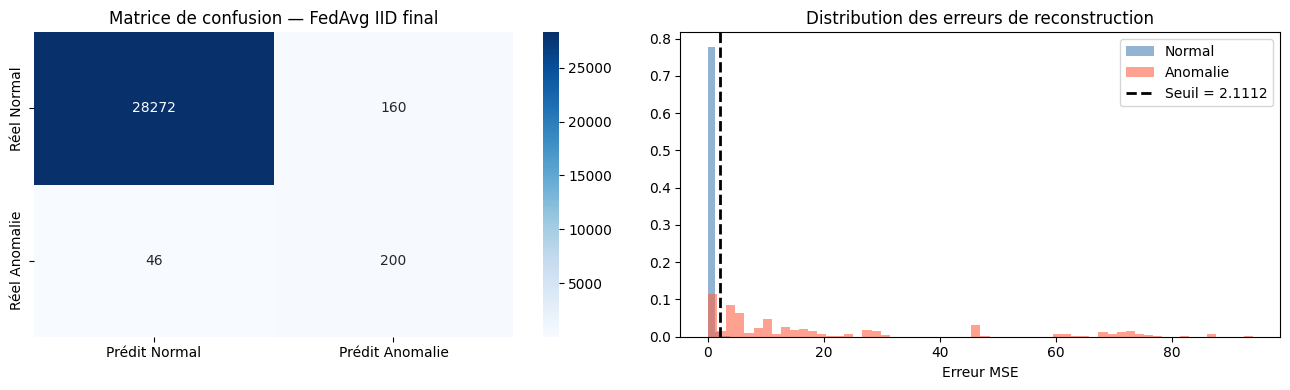

In [14]:
# Matrice de confusion finale
final_errors = reconstruction_error(model_fedavg, X_test_global)
final_thresh = hist_fedavg_iid['global_threshold'][-1]
y_pred_final = (final_errors > final_thresh).astype(int)

cm = confusion_matrix(y_test_global, y_pred_final)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Prédit Normal', 'Prédit Anomalie'],
            yticklabels=['Réel Normal',  'Réel Anomalie'])
axes[0].set_title('Matrice de confusion — FedAvg IID final')

# Distribution des erreurs
err_n = reconstruction_error(model_fedavg, X_test_normal_scaled)
err_a = reconstruction_error(model_fedavg, X_test_anomaly_scaled)
axes[1].hist(err_n, bins=60, alpha=0.6, label='Normal',   color='steelblue', density=True)
axes[1].hist(err_a, bins=60, alpha=0.6, label='Anomalie', color='tomato',    density=True)
axes[1].axvline(final_thresh, color='black', linestyle='--', linewidth=2,
                label=f'Seuil = {final_thresh:.4f}')
axes[1].set_title('Distribution des erreurs de reconstruction')
axes[1].set_xlabel('Erreur MSE')
axes[1].legend()

plt.tight_layout()
plt.show()


In [15]:
experiment_configs = {
    'FedAvg IID': {
        'num_clients': 3,
        'num_rounds': 10,
        'local_epochs': 1,
        'batch_size': 256,
        'strategy': 'fedavg',
        'partition': 'iid',
    },
    'FedAvg Non-IID': {
        'num_clients': 3,
        'num_rounds': 10,
        'local_epochs': 1,
        'batch_size': 256,
        'strategy': 'fedavg',
        'partition': 'non_iid',
    },
    'FedProx Non-IID': {
        'num_clients': 3,
        'num_rounds': 10,
        'local_epochs': 1,
        'batch_size': 256,
        'strategy': 'fedprox',
        'partition': 'non_iid',
        'mu': 0.01,
    },
}

hist_fedavg_noniid, client_hist_fedavg_noniid, model_fedavg_noniid = run_federated(
    **experiment_configs['FedAvg Non-IID'],
    verbose=False,
)

hist_fedprox_noniid, client_hist_fedprox_noniid, model_fedprox_noniid = run_federated(
    **experiment_configs['FedProx Non-IID'],
    verbose=False,
)

print('Expériences complémentaires exécutées :')
for name, config in experiment_configs.items():
    print(f'- {name}: {config}')


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        


INFO :      Starting Flower simulation, config: num_rounds=10, no round_timeout


2026-04-23 21:34:49,601	INFO worker.py:2012 -- Started a local Ray instance.


INFO :      Flower VCE: Ray initialized with resources: {'object_store_memory': 830405836.0, 'GPU': 1.0, 'memory': 1937613620.0, 'node:__internal_head__': 1.0, 'accelerator_type:G': 1.0, 'node:127.0.0.1': 1.0, 'CPU': 12.0}


INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html


...

INFO :      	         (8, 0.9663002811443422),


INFO :      	         (9, 0.9664901507976814),


INFO :      	         (10, 0.9666494239857987)]}


INFO :      


Expériences complémentaires exécutées :
- FedAvg IID: {'num_clients': 3, 'num_rounds': 10, 'local_epochs': 1, 'batch_size': 256, 'strategy': 'fedavg', 'partition': 'iid'}
- FedAvg Non-IID: {'num_clients': 3, 'num_rounds': 10, 'local_epochs': 1, 'batch_size': 256, 'strategy': 'fedavg', 'partition': 'non_iid'}
- FedProx Non-IID: {'num_clients': 3, 'num_rounds': 10, 'local_epochs': 1, 'batch_size': 256, 'strategy': 'fedprox', 'partition': 'non_iid', 'mu': 0.01}


## 8. Expériences complémentaires

En plus de l'expérience principale **FedAvg IID**, le notebook exécute :
- **FedAvg Non-IID** : pour mesurer l'impact d'une répartition hétérogène des transactions entre clients.
- **FedProx Non-IID** : bonus permettant de comparer FedAvg et FedProx lorsque les données sont non-IID.

## 9. FedProx dans Flower

Le terme proximal n'est pas codé manuellement dans une fonction séparée : il est pris en charge directement par Flower via `fl.server.strategy.FedProx`.

Le paramètre utilisé dans ce notebook est :
- `proximal_mu = 0.01`

Autrement dit, la logique FedProx est bien présente, mais elle est déléguée à l'implémentation officielle de Flower au lieu d'être réécrite à la main.

## 10. Visualisations

Les courbes **centralisées** et **fédérées** ne sont plus calculées de la même façon :
- **Centralisé** : évaluation du modèle global sur le jeu de test serveur complet.
- **Fédéré** : moyenne pondérée des évaluations du modèle global sur les jeux de test locaux des clients.

Le seuil n'est pas fixé arbitrairement : il est calibré sur le jeu de validation en testant plusieurs percentiles, puis appliqué au test final.

## 11. Conclusion

Le projet implémente un autoencodeur fédéré avec Flower sur `creditcard.csv`, entraîné uniquement sur les transactions normales. Le seuil de détection est choisi sur validation à partir d'un ensemble de percentiles, puis appliqué au test final. Les expériences montrent que la configuration **FedAvg IID** obtient de bonnes performances, que le cas **Non-IID** reste compétitif, et que **FedProx Non-IID** apporte un léger gain supplémentaire dans ce contexte.


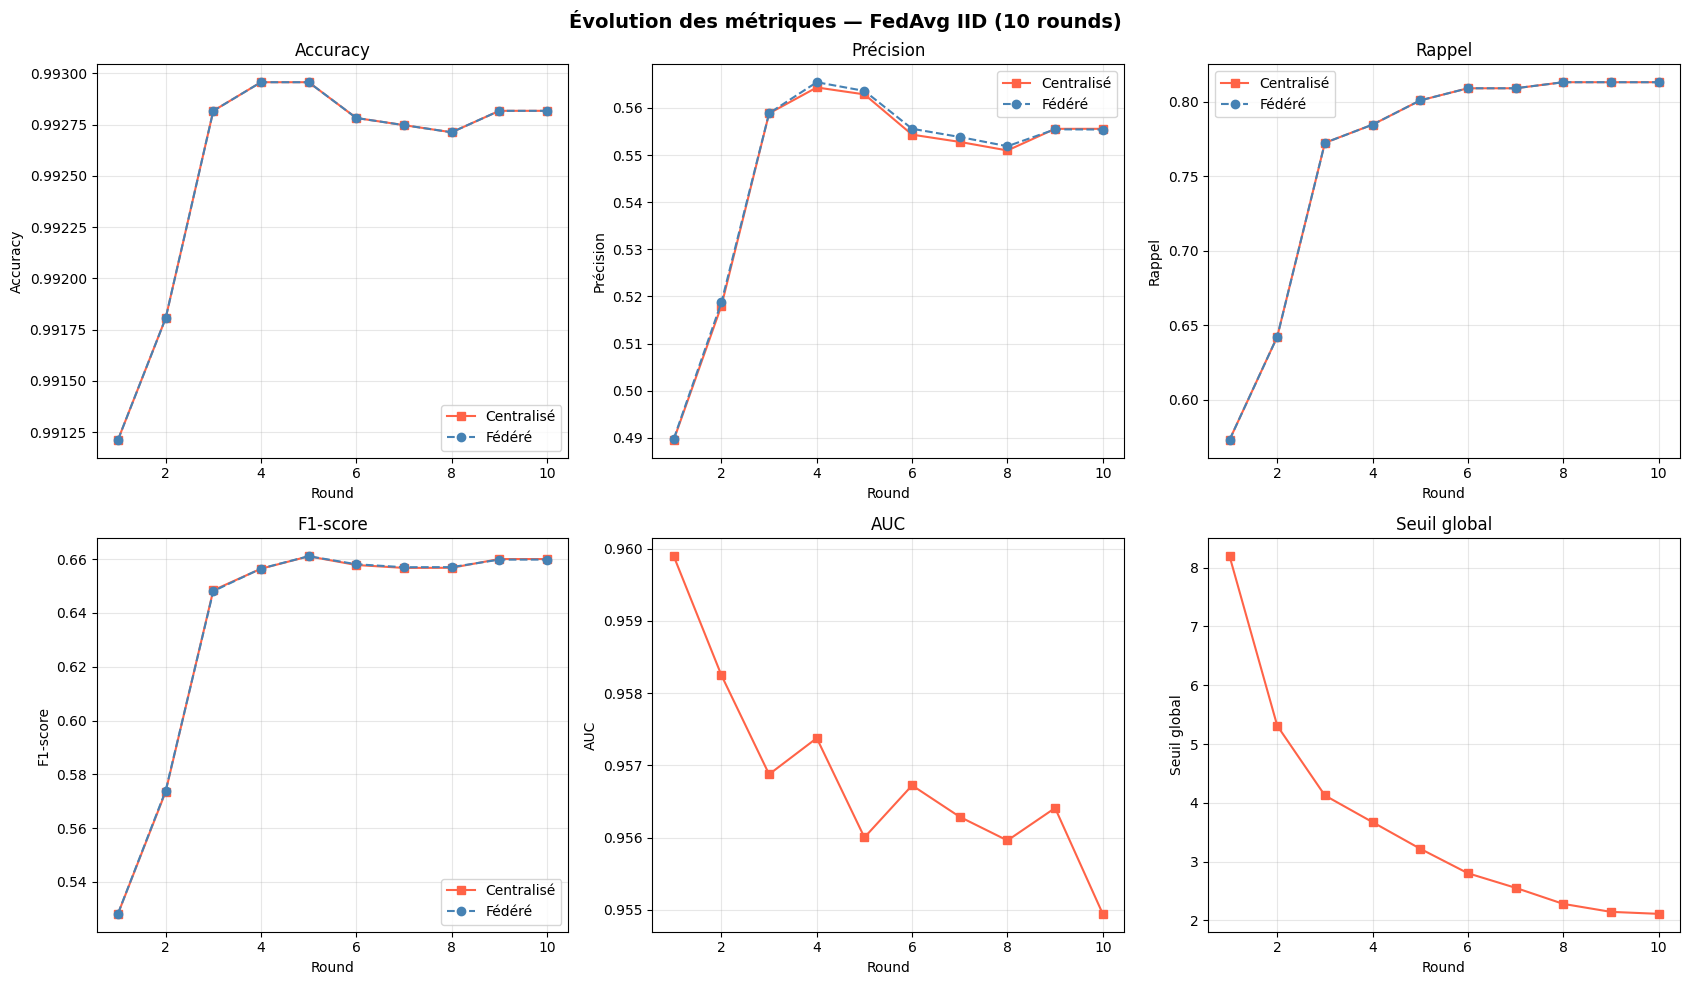

In [16]:
# Évolution complète des métriques (FedAvg IID, 10 rounds)
rounds = hist_fedavg_iid['round']
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle('Évolution des métriques — FedAvg IID (10 rounds)', fontsize=14, fontweight='bold')

metrics_plot = [
    ('accuracy',  'Accuracy',   'centralized_accuracy',  'federated_accuracy'),
    ('precision', 'Précision',  'centralized_precision', 'federated_precision'),
    ('recall',    'Rappel',     'centralized_recall',    'federated_recall'),
    ('f1',        'F1-score',   'centralized_f1',        'federated_f1'),
    ('auc',       'AUC',        'centralized_auc',       None),
    ('thresh',    'Seuil global', 'global_threshold',    None),
]

for ax, (key, label, cent_key, fed_key) in zip(axes.flat, metrics_plot):
    ax.plot(rounds, hist_fedavg_iid[cent_key], 's-', label='Centralisé', color='tomato')
    if fed_key:
        ax.plot(rounds, hist_fedavg_iid[fed_key], 'o--', label='Fédéré', color='steelblue')
    ax.set_title(label)
    ax.set_xlabel('Round')
    ax.set_ylabel(label)
    if fed_key:
        ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


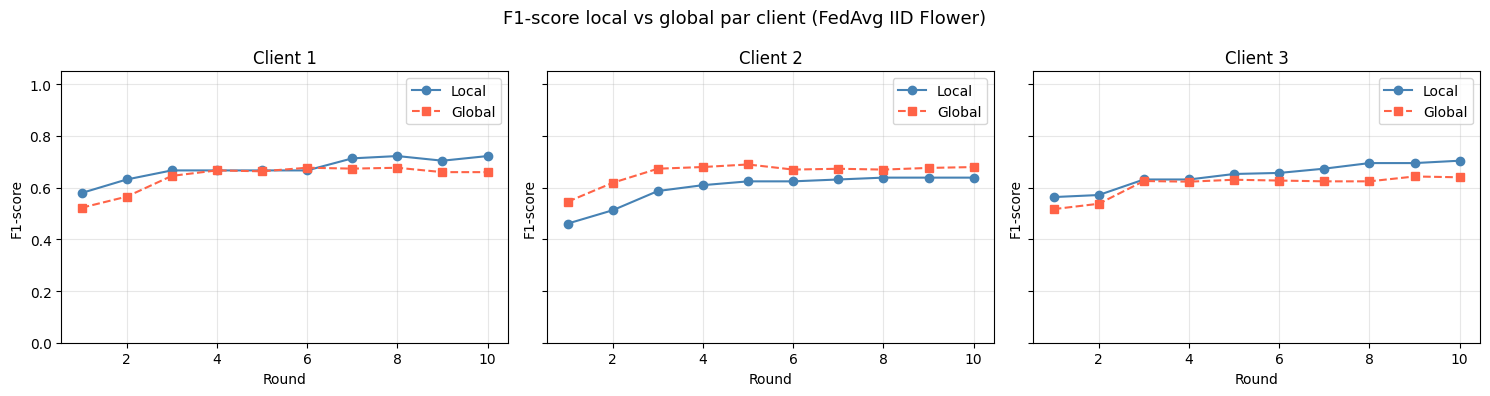

In [17]:
# F1-score local vs global par client (FedAvg IID Flower)
num_clients_plot = len(client_hist_fedavg)
fig, axes = plt.subplots(1, num_clients_plot, figsize=(5 * num_clients_plot, 4), sharey=True)
fig.suptitle('F1-score local vs global par client (FedAvg IID Flower)', fontsize=13)

if num_clients_plot == 1:
    axes = [axes]

for cid, ax in enumerate(axes):
    ax.plot(rounds, client_hist_fedavg[cid]['local_f1'], 'o-', label='Local', color='steelblue')
    ax.plot(rounds, client_hist_fedavg[cid]['global_f1'], 's--', label='Global', color='tomato')
    ax.set_title(f'Client {cid + 1}')
    ax.set_xlabel('Round')
    ax.set_ylabel('F1-score')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()


=== Synthèse finale ===
     expérience  rounds  percentile  validation_f1  federated_f1  centralized_f1  centralized_auc
     FedAvg IID      10        99.5         0.6655        0.6599          0.6601           0.9549
 FedAvg Non-IID      10        99.5         0.6107        0.6577          0.6257           0.9626
FedProx Non-IID      10        99.5         0.6230        0.7052          0.6620           0.9666


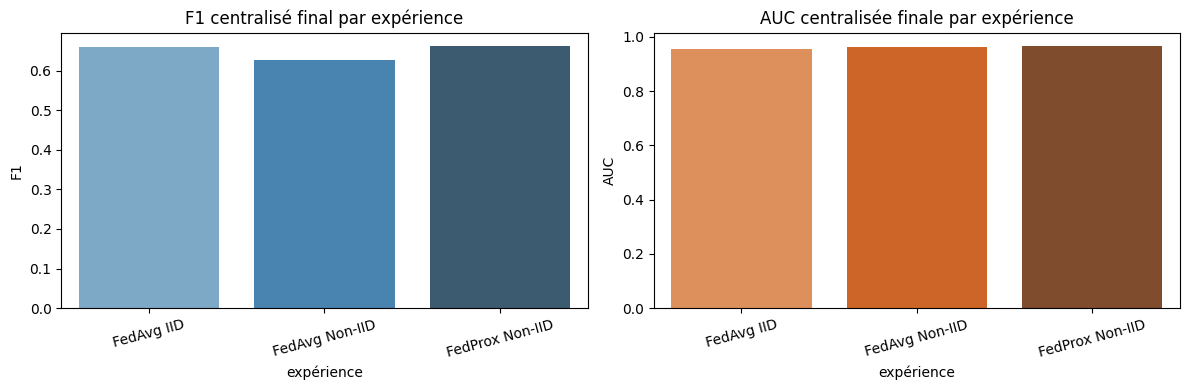

In [18]:
# Synthèse finale des expériences
experiment_results = pd.DataFrame([
    {
        'expérience': 'FedAvg IID',
        'rounds': hist_fedavg_iid['round'][-1],
        'percentile': hist_fedavg_iid['selected_percentile'][-1],
        'validation_f1': hist_fedavg_iid['validation_f1'][-1],
        'federated_f1': hist_fedavg_iid['federated_f1'][-1],
        'centralized_f1': hist_fedavg_iid['centralized_f1'][-1],
        'centralized_auc': hist_fedavg_iid['centralized_auc'][-1],
    },
    {
        'expérience': 'FedAvg Non-IID',
        'rounds': hist_fedavg_noniid['round'][-1],
        'percentile': hist_fedavg_noniid['selected_percentile'][-1],
        'validation_f1': hist_fedavg_noniid['validation_f1'][-1],
        'federated_f1': hist_fedavg_noniid['federated_f1'][-1],
        'centralized_f1': hist_fedavg_noniid['centralized_f1'][-1],
        'centralized_auc': hist_fedavg_noniid['centralized_auc'][-1],
    },
    {
        'expérience': 'FedProx Non-IID',
        'rounds': hist_fedprox_noniid['round'][-1],
        'percentile': hist_fedprox_noniid['selected_percentile'][-1],
        'validation_f1': hist_fedprox_noniid['validation_f1'][-1],
        'federated_f1': hist_fedprox_noniid['federated_f1'][-1],
        'centralized_f1': hist_fedprox_noniid['centralized_f1'][-1],
        'centralized_auc': hist_fedprox_noniid['centralized_auc'][-1],
    },
]).round(4)

print('=== Synthèse finale ===')
print(experiment_results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=experiment_results, x='expérience', y='centralized_f1', ax=axes[0], palette='Blues_d')
axes[0].set_title('F1 centralisé final par expérience')
axes[0].set_ylabel('F1')
axes[0].tick_params(axis='x', rotation=15)

sns.barplot(data=experiment_results, x='expérience', y='centralized_auc', ax=axes[1], palette='Oranges_d')
axes[1].set_title('AUC centralisée finale par expérience')
axes[1].set_ylabel('AUC')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()
